## The Data

At this link, you will find a dataset containing information about heart disease patients: https://www.dropbox.com/scl/fi/0vrpdnq5asmeulc4gd50y/ha_1.csv?rlkey=ciisalceotl77ffqhqe3kujzv&dl=1

A description of the original dataset can be found here: https://archive.ics.uci.edu/dataset/45/heart+disease (However, this dataset has been cleaned and reduced, and the people have been given fictious names.)

## 1. Logistic Regression

Fit a Logistic Regression using only `age` and `chol` (cholesterol) as predictors.

For a 55 year old, how high would their cholesterol need to be for the doctors to predict heart disease is present?

How high for the doctors to estimate a 90% chance that heart disease is present?

In [9]:
import numpy as np
import pandas as pd
from plotnine import aes, coord_cartesian, geom_abline, geom_point, ggplot, labs
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

heart = pd.read_csv("https://www.dropbox.com/scl/fi/0vrpdnq5asmeulc4gd50y/ha_1.csv?rlkey=ciisalceotl77ffqhqe3kujzv&dl=1")
X = heart[["age", "chol"]]
y = (heart["diagnosis"] == "Disease").astype(int)

logit = LogisticRegression(max_iter=1000)
logit.fit(X, y)

logit_age, logit_chol = logit.coef_[0]
logit_intercept = logit.intercept_[0]

chol_50 = (0 - logit_intercept - logit_age * 55) / logit_chol
chol_90 = (np.log(0.90 / 0.10) - logit_intercept - logit_age * 55) / logit_chol

print("Cholesterol at 50%:", round(chol_50, 2))
print("Cholesterol at 90%:", round(chol_90, 2))

Cholesterol at 50%: 367.87
Cholesterol at 90%: -851.97


At age 55, the fitted logistic regression predicts disease below **367.87 mg/dL**. The predicted probability is 50% at the cutoff. The equation reaches 90% at **−851.97 mg/dL**, so the model never reaches 90% at a nonnegative cholesterol value.

## 2. Linear Discriminant Analysis

Fit an LDA model using only `age` and `chol` (cholesterol)  as predictors.

For a 55 year old, how high would their cholesterol need to be for the doctors to predict heart disease is present?

In [10]:
lda = LinearDiscriminantAnalysis()
lda.fit(X, y)

lda_age, lda_chol = lda.coef_[0]
lda_intercept = lda.intercept_[0]

chol_lda = (0 - lda_intercept - lda_age * 55) / lda_chol
print("LDA cholesterol cutoff:", round(chol_lda, 2))

LDA cholesterol cutoff: 366.83


At age 55, LDA predicts disease below **366.83 mg/dL**.

## 3. Support Vector Classifier

Fit an SVC model using only `age` and `chol` as predictors.  Don't forget to tune the regularization parameter.

For a 55 year old, how high would their cholesterol need to be for the doctors to predict heart disease is present?

In [11]:
svc_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("svc", SVC(kernel="linear"))
])

svc_grid = {"svc__C": [0.001, 0.01, 0.1, 1, 10, 100]}
svc_search = GridSearchCV(svc_pipeline, svc_grid, cv=5, scoring="accuracy")
svc_search.fit(X, y)

svc_fitted = svc_search.best_estimator_
scaler = svc_fitted.named_steps["scale"]
svc = svc_fitted.named_steps["svc"]

svc_weights = svc.coef_[0] / scaler.scale_
svc_age, svc_chol = svc_weights
svc_intercept = svc.intercept_[0] - sum(svc_weights * scaler.mean_)

chol_svc = (0 - svc_intercept - svc_age * 55) / svc_chol

print("Best C:", svc_search.best_params_["svc__C"])
print("SVC cholesterol cutoff:", round(chol_svc, 2))

Best C: 10
SVC cholesterol cutoff: 312.66


Five-fold cross-validation selected **C = 10** using accuracy. At age 55, the fitted linear SVC predicts disease below **312.66 mg/dL**.

## 4. Comparing Decision Boundaries

Make a scatterplot of `age` and `chol`, coloring the points by their true disease outcome.  Add a line to the plot representing the **linear separator** (aka **decision boundary**) for each of the three models above.

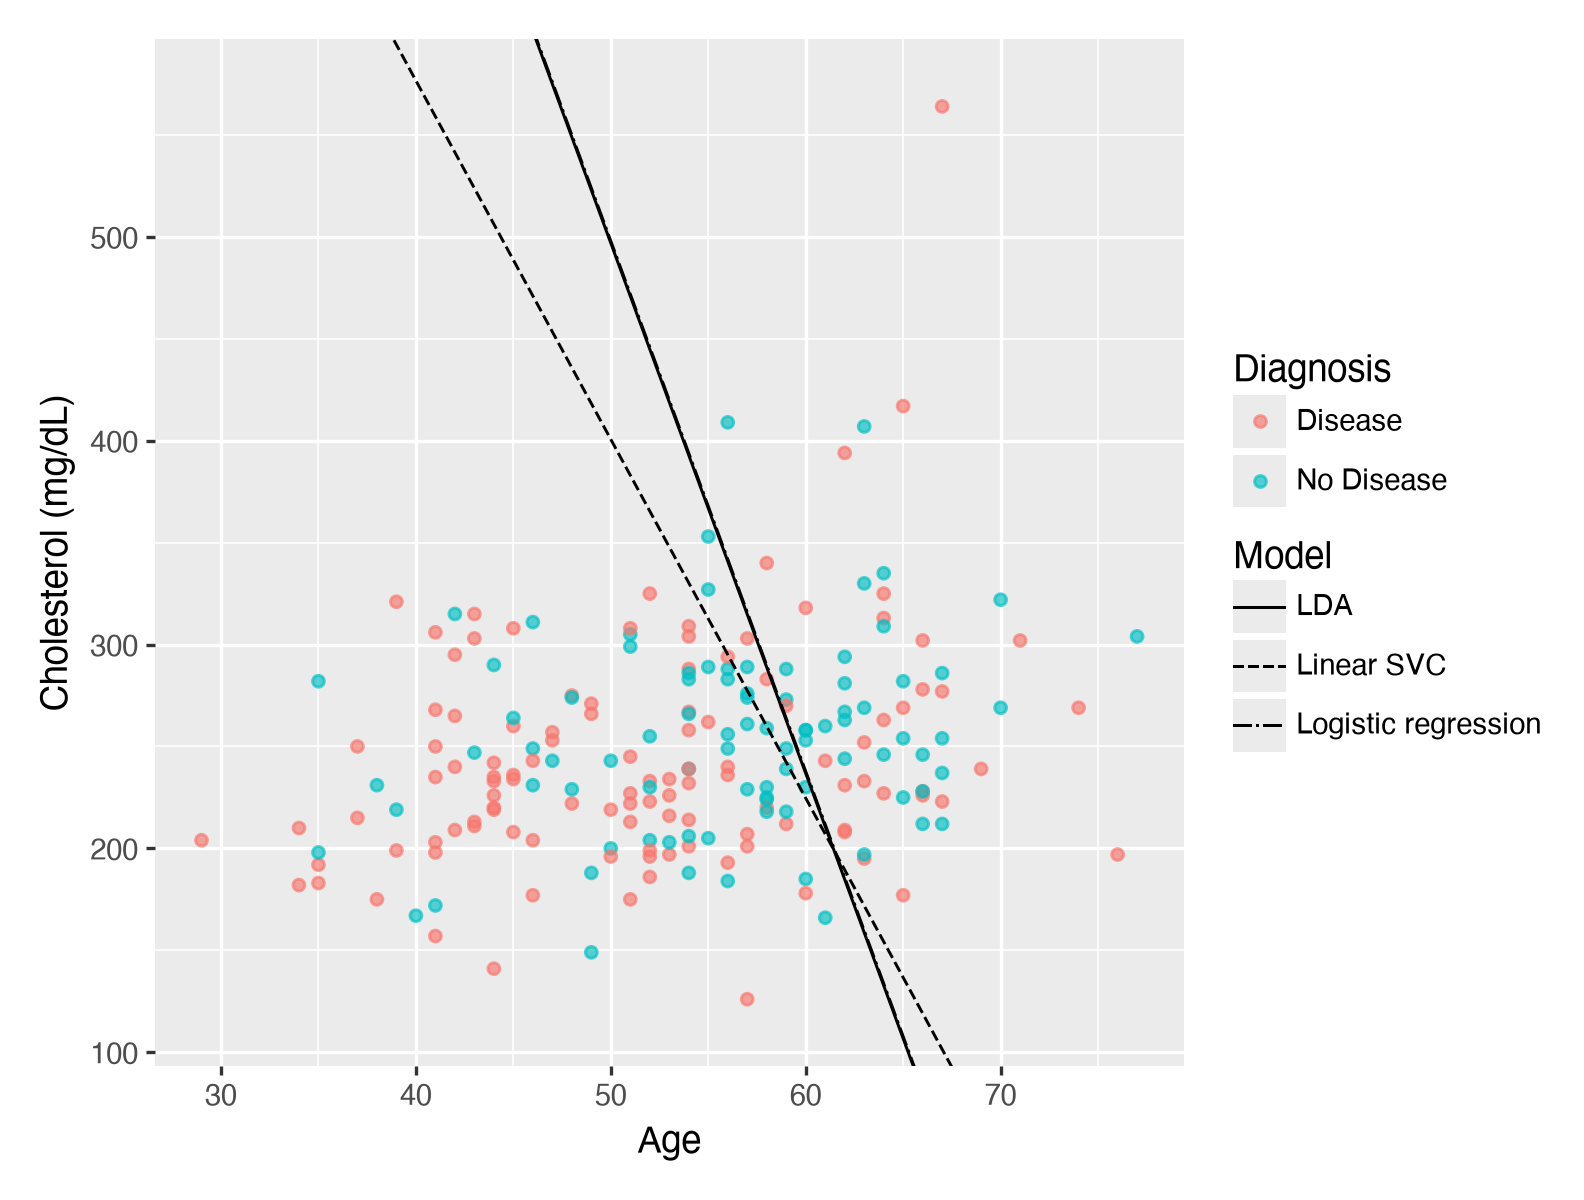

In [12]:
boundaries = pd.DataFrame({
    "model": ["Logistic regression", "LDA", "Linear SVC"],
    "slope": [-logit_age / logit_chol, -lda_age / lda_chol, -svc_age / svc_chol],
    "intercept": [-logit_intercept / logit_chol, -lda_intercept / lda_chol, -svc_intercept / svc_chol]
})

plot = ggplot(heart, aes(x="age", y="chol", color="diagnosis"))
plot = plot + geom_point(alpha=0.65)
plot = plot + geom_abline(
    data=boundaries,
    mapping=aes(slope="slope", intercept="intercept", linetype="model"),
    color="black"
)
plot = plot + coord_cartesian(ylim=(heart["chol"].min() - 10, heart["chol"].max() + 10))
plot + labs(x="Age", y="Cholesterol (mg/dL)", color="Diagnosis", linetype="Model")